# Clinical Escalation: Recommending the Next Action from Bedside Monitoring

## Introduction

On a busy ward, a nurse looking at a patient's monitor is really answering one question
many times an hour: **what do I do next?** Keep observing, come back in fifteen minutes,
call the medical registrar, or escalate to critical care. That decision is made from a
handful of numbers, and it is made under time pressure with more patients than staff.

### The Escalation Challenge

A bedside decision has to balance several things at once:
- **Distance to an alarm threshold** (how much headroom is left on each channel)
- **Direction of travel** (is the patient improving or declining?)
- **Patient acuity** (how much reserve does this patient have?)
- **Staffing reality** (how soon can anyone realistically come back?)

### Machine Learning Solution

This is a **supervised classification problem**:
- **Input features**: monitoring margins and ward context
- **Output**: the recommended escalation action
- **Goal**: learn the escalation rules from examples of real decisions

The point of the exercise is that the rules a ward writes down in an escalation policy
can be recovered from examples alone. A tree trained on decisions will rediscover the
thresholds, and it will tell you which of them actually drives practice.

> **About the data.** Every patient in this notebook is simulated from published
> physiological reference ranges. No real or identifiable patient data is used.

### What You'll Learn

1. How to frame a bedside escalation decision as a supervised learning problem
2. Creating and exploring synthetic monitoring data
3. Training and comparing multiple ML algorithms (Decision Trees, Random Forest, XGBoost)
4. Visualizing escalation decisions the way a bedside display would
5. Interpreting which monitoring channels drive the recommendation
6. Interactive exploration of escalation scenarios

Let's begin. 🩺


## Setup and Imports

In [1]:
# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Circle, Rectangle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb

# Model interpretation
import shap

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown

# Set random seed for reproducibility
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


## 1. Dataset Generation

### Monitoring Features

Every channel on a monitor has an alarm threshold. What matters clinically is not the raw
number, it is **how much headroom is left before the alarm fires** — and that is what we
record. A margin of zero means the patient is sitting exactly on the threshold.

1. **SpO2 margin** (percentage points above the 92 % alarm threshold)
2. **MAP margin** (mmHg above the 65 mmHg mean arterial pressure threshold)
3. **Heart rate margin** (bpm below the 120 bpm tachycardia threshold)
4. **Minutes since check** (0-120): how long since the last set of observations
5. **Nurse-to-patient ratio** (1-8): patients this nurse is currently carrying
6. **Acuity level** (1-5): how much physiological reserve the patient has
7. **Trend slope** (-3 to +3): negative means declining, positive means improving

### Escalation Actions

- **ROUTINE**: continue routine observation
- **RECHECK_15MIN**: recheck in 15 minutes
- **CALL_REGISTRAR**: call the medical registrar
- **ESCALATE_CRITICAL**: escalate to critical care

### Decision Logic for Synthetic Data

We write the labels using the escalation policy a ward would actually publish:
- Any channel already past its alarm threshold → ESCALATE_CRITICAL
- A channel close to its threshold → CALL_REGISTRAR if declining, otherwise RECHECK_15MIN
- Observations overdue on an acutely unwell patient → RECHECK_15MIN
- A clearly declining trend on a patient with little reserve → CALL_REGISTRAR
- Everything comfortable → ROUTINE

We then add 5 % label noise, because real escalation decisions are not perfectly
consistent between clinicians. The model still has to find the rules underneath.


In [2]:
# The four escalation actions, in order of increasing urgency
ACTION_ORDER = ['ROUTINE', 'RECHECK_15MIN', 'CALL_REGISTRAR', 'ESCALATE_CRITICAL']

ACTION_LABELS = {
    'ROUTINE': 'Continue routine observation',
    'RECHECK_15MIN': 'Recheck in 15 minutes',
    'CALL_REGISTRAR': 'Call the medical registrar',
    'ESCALATE_CRITICAL': 'Escalate to critical care',
}

# Alarm thresholds each margin is measured against
SPO2_ALARM = 92.0    # %      - margin is points ABOVE this
MAP_ALARM = 65.0     # mmHg   - margin is mmHg ABOVE this
HR_ALARM = 120.0     # bpm    - margin is bpm BELOW this


def generate_escalation_action_data(n_samples=2000):
    """
    Generate synthetic bedside escalation data with realistic decision rules.

    Features are the numbers a nurse has in front of them: how much headroom is
    left on each monitored channel, how long since the last check, how heavily
    staffed the bay is, how sick the patient is and which way they are moving.

    All values are simulated from published reference ranges. No real or
    identifiable patient data is used.

    Parameters:
    -----------
    n_samples : int
        Number of bedside scenarios to generate

    Returns:
    --------
    X : DataFrame
        Feature matrix with monitoring margins and ward context
    y : Series
        Recommended escalation action (target labels)
    """

    # Generate monitoring margins and ward context
    data = {
        # SpO2 92-101 % -> margin -1 to +9 points above the 92 % alarm
        'spo2_margin': np.random.uniform(-1, 9, n_samples),
        # MAP 60-110 mmHg -> margin -5 to +45 mmHg above the 65 mmHg alarm
        'map_margin': np.random.uniform(-5, 45, n_samples),
        # Heart rate 48-128 bpm -> margin -8 to +72 bpm below the 120 bpm alarm
        'hr_margin': np.random.uniform(-8, 72, n_samples),
        # Minutes since the last set of observations
        'minutes_since_check': np.random.uniform(0, 120, n_samples),
        # Patients this nurse is currently carrying
        'nurse_patient_ratio': np.random.uniform(1, 8, n_samples),
        # Acuity 1 (plenty of reserve) to 5 (almost none)
        'acuity_level': np.random.choice([1, 2, 3, 4, 5], n_samples,
                                         p=[0.15, 0.25, 0.30, 0.20, 0.10]),
        # Trend over the last hour: negative = declining, positive = improving
        'trend_slope': np.random.uniform(-3, 3, n_samples)
    }

    X = pd.DataFrame(data)

    # Apply the ward escalation policy
    actions = []

    for i in range(n_samples):
        spo2_m = X.loc[i, 'spo2_margin']
        map_m = X.loc[i, 'map_margin']
        hr_m = X.loc[i, 'hr_margin']
        since = X.loc[i, 'minutes_since_check']
        ratio = X.loc[i, 'nurse_patient_ratio']
        acuity = X.loc[i, 'acuity_level']
        trend = X.loc[i, 'trend_slope']

        # Priority 1: a channel has already crossed its alarm threshold
        if spo2_m < 0 or map_m < 0 or hr_m < 0:
            action = 'ESCALATE_CRITICAL'

        # Priority 2: a channel is within touching distance of its threshold
        elif spo2_m < 2 or map_m < 8 or hr_m < 12:
            # A patient who is declining needs a doctor now;
            # one who is holding steady needs another look shortly.
            if trend < -0.5:
                action = 'CALL_REGISTRAR'
            else:
                action = 'RECHECK_15MIN'

        # Priority 3: observations overdue on a patient with little reserve
        elif since > 60 and acuity >= 4:
            action = 'RECHECK_15MIN'

        # Priority 4: a clearly declining trend on an acutely unwell patient
        elif trend < -1.5 and acuity >= 3:
            action = 'CALL_REGISTRAR'

        # Priority 5: thin staffing means an unwell patient needs a booked recheck
        elif ratio > 6 and acuity >= 4:
            action = 'RECHECK_15MIN'

        # Default: comfortable headroom on every channel
        else:
            action = 'ROUTINE'

        actions.append(action)

    y = pd.Series(actions, name='action')

    # Add some noise (5% of decisions differ between clinicians)
    noise_indices = np.random.choice(n_samples, size=int(0.05 * n_samples), replace=False)
    for idx in noise_indices:
        y.iloc[idx] = np.random.choice(ACTION_ORDER)

    return X, y

# Generate dataset
X, y = generate_escalation_action_data(n_samples=2000)

print("\U0001fa7a Escalation Dataset Generated (simulated, no real patient data)")
print(f"Dataset shape: {X.shape}")
print(f"\nFeatures: {list(X.columns)}")
print(f"\nAction distribution:\n{y.value_counts()}")
print(f"\nFirst few samples:")
pd.concat([X.head(), y.head()], axis=1)


🩺 Escalation Dataset Generated (simulated, no real patient data)
Dataset shape: (2000, 7)

Features: ['spo2_margin', 'map_margin', 'hr_margin', 'minutes_since_check', 'nurse_patient_ratio', 'acuity_level', 'trend_slope']

Action distribution:
action
ESCALATE_CRITICAL    560
ROUTINE              537
RECHECK_15MIN        527
CALL_REGISTRAR       376
Name: count, dtype: int64

First few samples:


,spo2_margin,map_margin,hr_margin,minutes_since_check,nurse_patient_ratio,acuity_level,trend_slope,action
0,2.745401,8.085284,37.759670,77.790834,6.041875,2,0.925838,ROUTINE
1,8.507143,7.348940,56.434586,20.686363,5.810981,2,-2.519805,CALL_REGISTRAR
2,6.319939,40.312729,52.812874,104.687348,1.670279,2,-1.546021,ROUTINE
3,4.986585,7.477310,4.311992,73.573949,7.458007,3,1.642076,RECHECK_15MIN
4,0.560186,8.597486,3.939958,18.864466,4.979305,3,0.172115,RECHECK_15MIN


## 2. Exploratory Data Analysis

Let's visualize the monitoring margins and understand how they relate to the recommended
action.


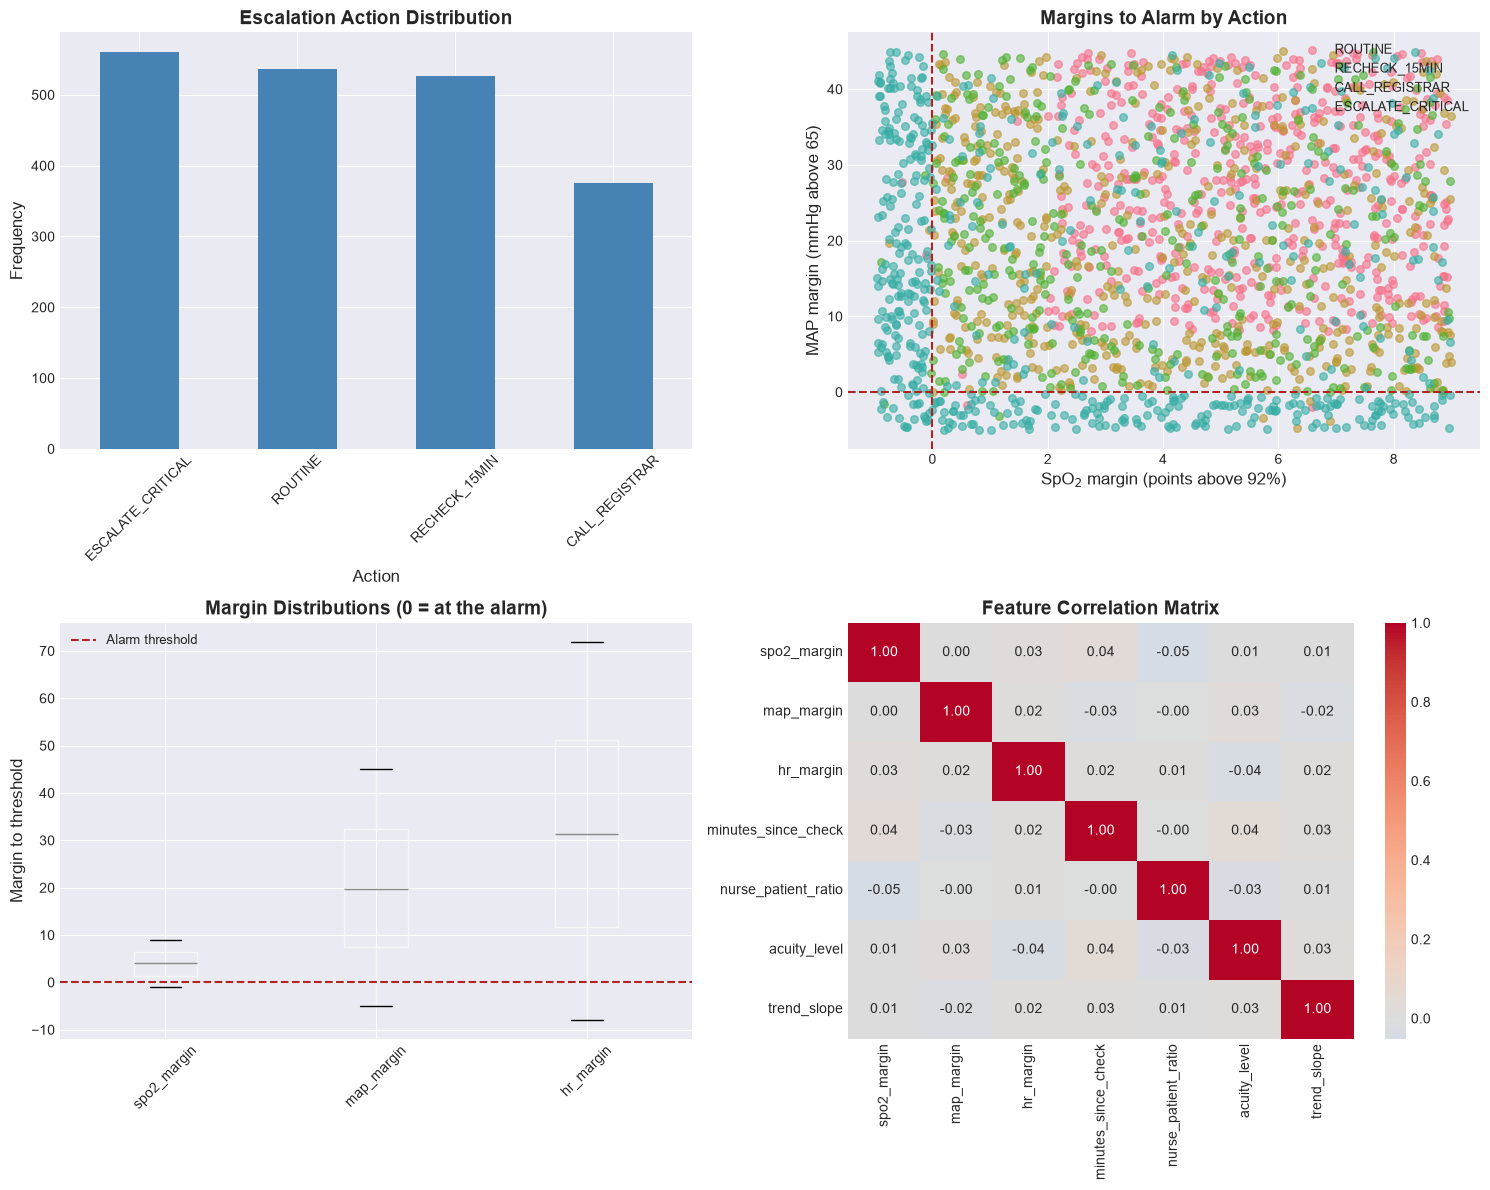


📊 Key Observations:
- ESCALATE_CRITICAL occurs when any margin falls below zero
- CALL_REGISTRAR clusters where a margin is small AND the trend is declining
- Margins are close to independent, as separate monitoring channels should be


In [3]:
# Create a combined dataframe for visualization
df_viz = pd.concat([X, y], axis=1)

# Action distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Action frequency
ax1 = axes[0, 0]
y.value_counts().plot(kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Escalation Action Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Action', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

# 2. SpO2 margin vs MAP margin coloured by action
ax2 = axes[0, 1]
for action in ACTION_ORDER:
    mask = y == action
    ax2.scatter(X.loc[mask, 'spo2_margin'], X.loc[mask, 'map_margin'],
                label=action, alpha=0.6, s=30)
ax2.axvline(0, color='firebrick', linestyle='--', linewidth=1.5)
ax2.axhline(0, color='firebrick', linestyle='--', linewidth=1.5)
ax2.set_xlabel('SpO$_2$ margin (points above 92%)', fontsize=12)
ax2.set_ylabel('MAP margin (mmHg above 65)', fontsize=12)
ax2.set_title('Margins to Alarm by Action', fontsize=14, fontweight='bold')
ax2.legend(fontsize=9)

# 3. Distribution of the three margins
ax3 = axes[1, 0]
X[['spo2_margin', 'map_margin', 'hr_margin']].boxplot(ax=ax3)
ax3.axhline(0, color='firebrick', linestyle='--', linewidth=1.5, label='Alarm threshold')
ax3.set_title('Margin Distributions (0 = at the alarm)', fontsize=14, fontweight='bold')
ax3.set_ylabel('Margin to threshold', fontsize=12)
ax3.tick_params(axis='x', rotation=45)
ax3.legend(fontsize=9)

# 4. Feature correlation heatmap
ax4 = axes[1, 1]
corr = X.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax4)
ax4.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n\U0001f4ca Key Observations:")
print("- ESCALATE_CRITICAL occurs when any margin falls below zero")
print("- CALL_REGISTRAR clusters where a margin is small AND the trend is declining")
print("- Margins are close to independent, as separate monitoring channels should be")


### Margin Distributions by Recommended Action

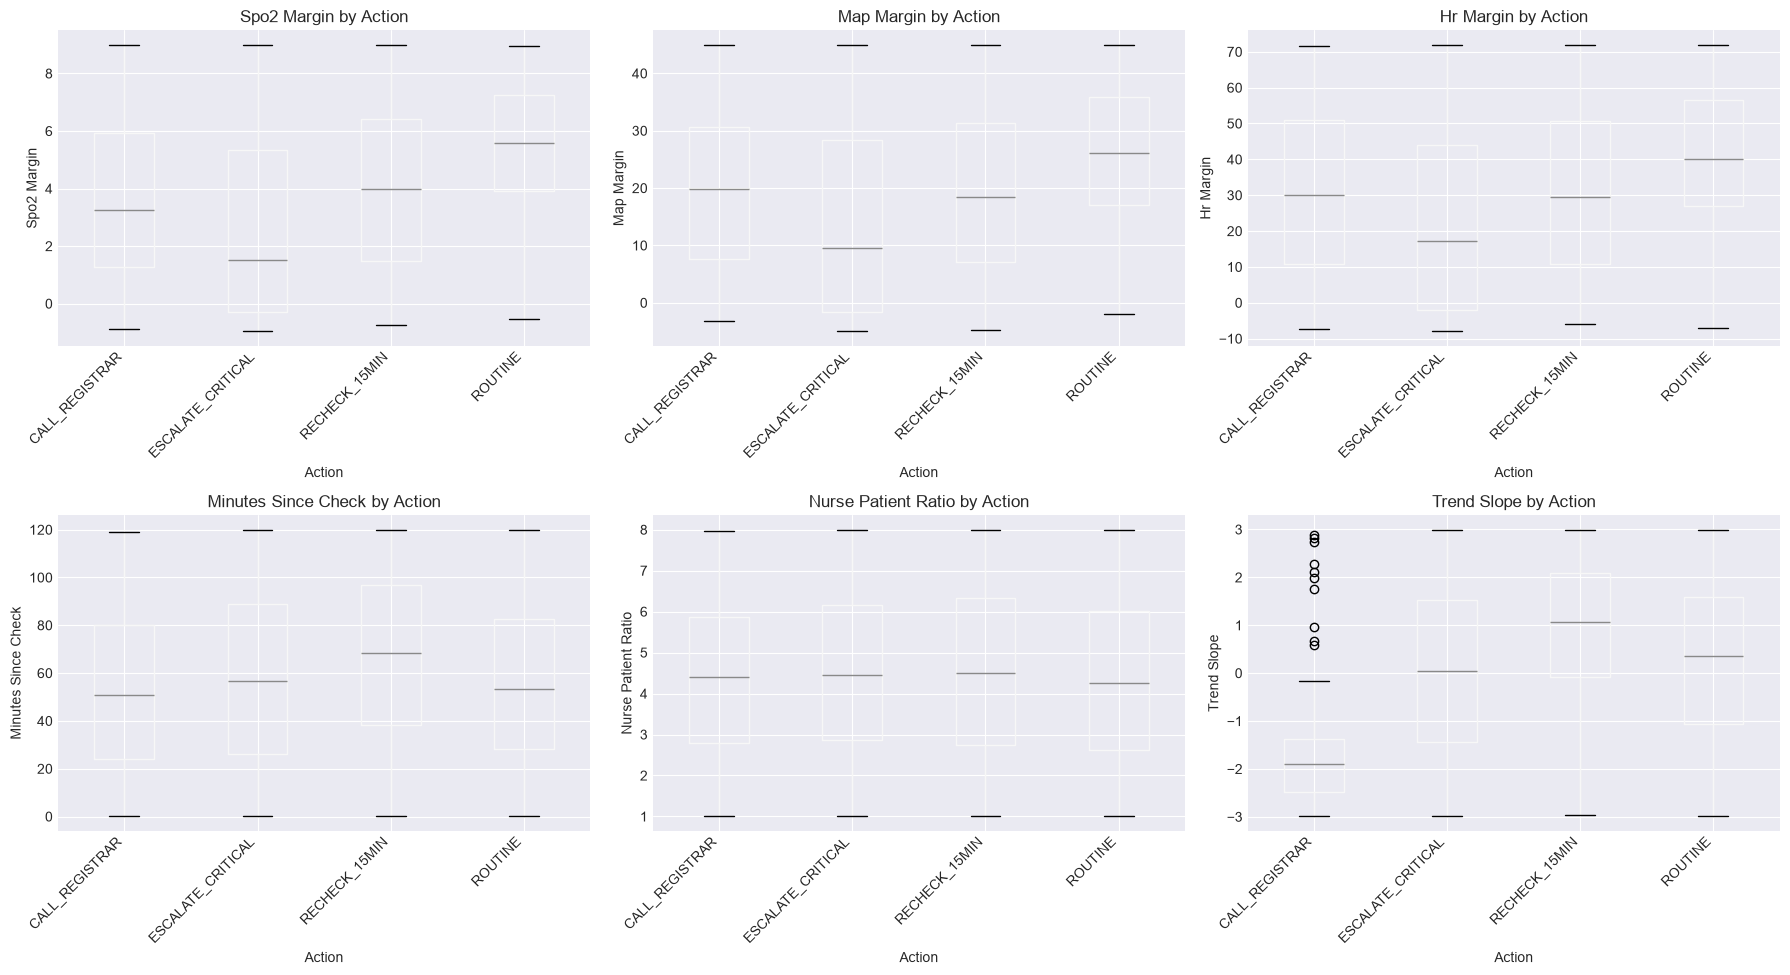

In [4]:
# Box plots showing feature distributions for each action
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

features_to_plot = ['spo2_margin', 'map_margin', 'hr_margin',
                    'minutes_since_check', 'nurse_patient_ratio', 'trend_slope']

for idx, feature in enumerate(features_to_plot):
    ax = axes[idx]
    df_viz.boxplot(column=feature, by='action', ax=ax)
    ax.set_title(f'{feature.replace("_", " ").title()} by Action', fontsize=12)
    ax.set_xlabel('Action', fontsize=10)
    ax.set_ylabel(feature.replace('_', ' ').title(), fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    plt.sca(ax)
    plt.xticks(rotation=45, ha='right')

# Remove the automatic title added by boxplot
for ax in axes:
    ax.get_figure().suptitle('')

plt.tight_layout()
plt.show()


## 3. Train-Test Split

In [5]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} scenarios")
print(f"Testing set size: {X_test.shape[0]} scenarios")
print(f"\nTraining set action distribution:\n{y_train.value_counts()}")


Training set size: 1600 scenarios
Testing set size: 400 scenarios

Training set action distribution:
action
ESCALATE_CRITICAL    448
ROUTINE              430
RECHECK_15MIN        421
CALL_REGISTRAR       301
Name: count, dtype: int64


### Encode Labels for XGBoost

XGBoost requires numeric labels, so we'll create encoded versions for that model while keeping string labels for Decision Tree and Random Forest.

In [6]:
# Label encoding for XGBoost (which needs numeric labels)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Store the mapping for reference
label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Label Encoding Mapping:")
for action, code in sorted(label_mapping.items()):
    print(f"  {action}: {code}")

Label Encoding Mapping:
  CALL_REGISTRAR: 0
  ESCALATE_CRITICAL: 1
  RECHECK_15MIN: 2
  ROUTINE: 3


## 4. Model Training and Comparison

We'll train three different models and compare their performance:

1. **Decision Tree**: simple rules a clinician can read straight off the page
2. **Random Forest**: an ensemble of trees for better generalization
3. **XGBoost**: gradient boosting for the strongest performance


### 4.1 Decision Tree Classifier

In [7]:
# Train Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluation
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {dt_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9050

Classification Report:
                   precision    recall  f1-score   support

   CALL_REGISTRAR       0.80      0.91      0.85        75
ESCALATE_CRITICAL       0.97      0.96      0.96       112
    RECHECK_15MIN       0.87      0.87      0.87       106
          ROUTINE       0.96      0.89      0.92       107

         accuracy                           0.91       400
        macro avg       0.90      0.90      0.90       400
     weighted avg       0.91      0.91      0.91       400



### Visualize Decision Tree Structure

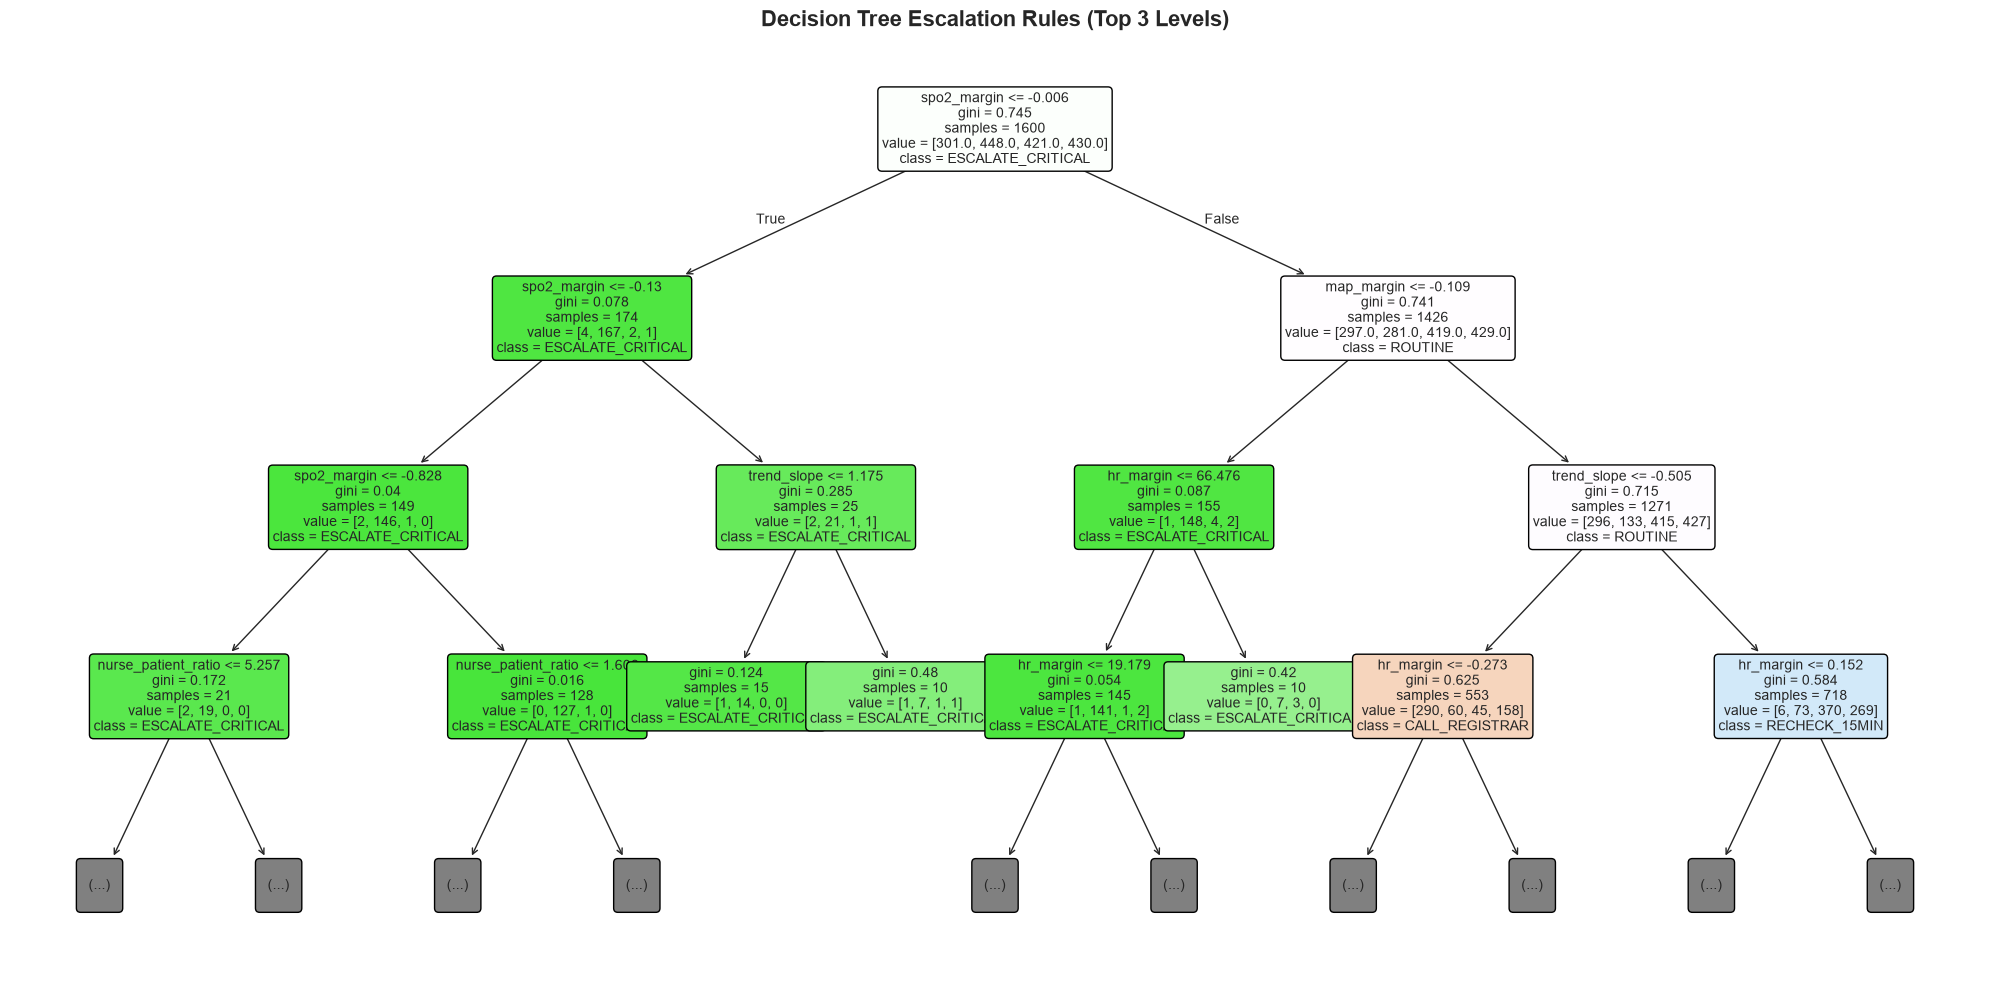


🌳 The tree shows the escalation rules recovered from the decisions alone.
   Each node splits on a margin, a trend or a piece of ward context -
   compare the thresholds it found with the policy we wrote by hand.


In [8]:
# Plot simplified decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3  # Show only top 3 levels for clarity
)
plt.title('Decision Tree Escalation Rules (Top 3 Levels)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n\U0001f333 The tree shows the escalation rules recovered from the decisions alone.")
print("   Each node splits on a margin, a trend or a piece of ward context -")
print("   compare the thresholds it found with the policy we wrote by hand.")


### 4.2 Random Forest Classifier

In [9]:
# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {rf_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9375

Classification Report:
                   precision    recall  f1-score   support

   CALL_REGISTRAR       0.83      0.95      0.88        75
ESCALATE_CRITICAL       0.97      0.96      0.97       112
    RECHECK_15MIN       0.96      0.89      0.92       106
          ROUTINE       0.97      0.95      0.96       107

         accuracy                           0.94       400
        macro avg       0.93      0.94      0.93       400
     weighted avg       0.94      0.94      0.94       400



### 4.3 XGBoost Classifier

In [10]:
# Train XGBoost (using encoded labels)
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.1,
    random_state=42,
    eval_metric='mlogloss'
)

xgb_model.fit(X_train, y_train_encoded)

# Predictions (decode back to original labels)
y_pred_xgb_encoded = xgb_model.predict(X_test)
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

# Evaluation
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Accuracy: {xgb_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9550

Classification Report:
                   precision    recall  f1-score   support

   CALL_REGISTRAR       0.90      0.96      0.93        75
ESCALATE_CRITICAL       0.96      0.96      0.96       112
    RECHECK_15MIN       0.97      0.92      0.95       106
          ROUTINE       0.97      0.98      0.98       107

         accuracy                           0.95       400
        macro avg       0.95      0.96      0.95       400
     weighted avg       0.96      0.95      0.96       400



### Model Performance Comparison

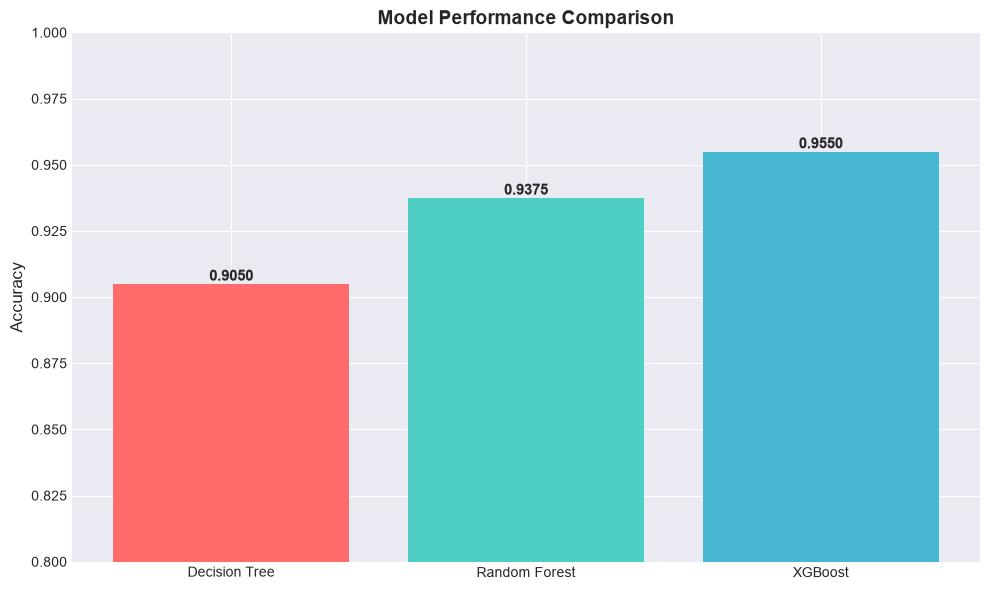


📈 Model Comparison Summary:
        Model  Accuracy
Decision Tree    0.9050
Random Forest    0.9375
      XGBoost    0.9550


In [11]:
# Compare model accuracies
models_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'XGBoost'],
    'Accuracy': [dt_accuracy, rf_accuracy, xgb_accuracy]
})

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models_comparison['Model'], models_comparison['Accuracy'], 
               color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylim([0.8, 1.0])

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n📈 Model Comparison Summary:")
print(models_comparison.to_string(index=False))

### Confusion Matrices

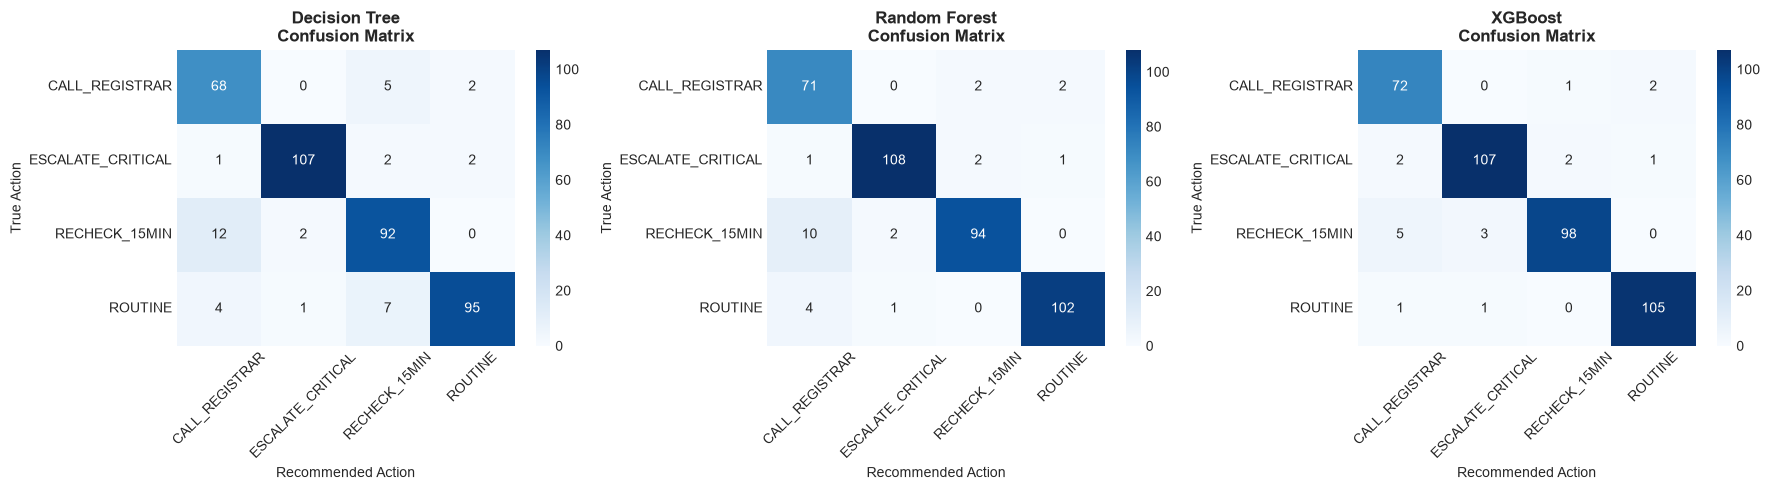

In [12]:
# Plot confusion matrices for all models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_data = [
    ('Decision Tree', y_pred_dt),
    ('Random Forest', y_pred_rf),
    ('XGBoost', y_pred_xgb)
]

for idx, (model_name, y_pred) in enumerate(models_data):
    ax = axes[idx]
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=dt_model.classes_,
                yticklabels=dt_model.classes_)
    ax.set_title(f'{model_name}\nConfusion Matrix', fontsize=12, fontweight='bold')
    ax.set_ylabel('True Action', fontsize=10)
    ax.set_xlabel('Recommended Action', fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()


## 5. Feature Importance Analysis

Which monitoring channels actually drive the escalation recommendation?


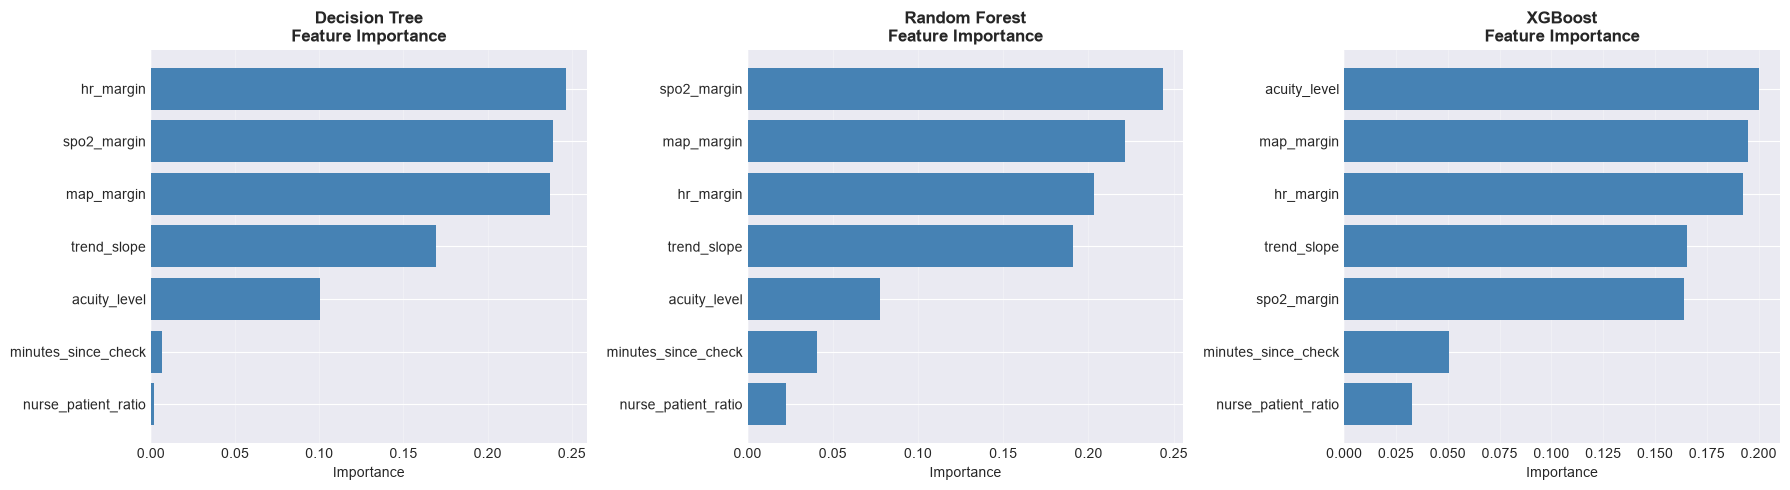


🎯 Key Insights:
   The features that matter most for the escalation decision are typically:
   1. The three margins to alarm (how much headroom is left)
   2. Trend slope (which way the patient is moving)
   3. Acuity level and time since the last check (how much reserve, how stale the data)

   Note how little weight nurse-to-patient ratio carries: it shapes only a
   narrow corner of the policy, and the model has correctly worked that out.


In [13]:
# Compare feature importance across models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_importance = [
    ('Decision Tree', dt_model.feature_importances_),
    ('Random Forest', rf_model.feature_importances_),
    ('XGBoost', xgb_model.feature_importances_)
]

for idx, (model_name, importances) in enumerate(models_importance):
    ax = axes[idx]
    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': importances
    }).sort_values('Importance', ascending=True)

    ax.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
    ax.set_xlabel('Importance', fontsize=10)
    ax.set_title(f'{model_name}\nFeature Importance', fontsize=12, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n\U0001f3af Key Insights:")
print("   The features that matter most for the escalation decision are typically:")
print("   1. The three margins to alarm (how much headroom is left)")
print("   2. Trend slope (which way the patient is moving)")
print("   3. Acuity level and time since the last check (how much reserve, how stale the data)")
print("\n   Note how little weight nurse-to-patient ratio carries: it shapes only a")
print("   narrow corner of the policy, and the model has correctly worked that out.")


## 6. SHAP Analysis - Deep Model Interpretation

SHAP (SHapley Additive exPlanations) values show how each feature contributes to individual predictions.

In [14]:
# Calculate SHAP values for XGBoost model
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# Note: SHAP values are calculated using the model's internal representation
print("✓ SHAP values calculated successfully!")

✓ SHAP values calculated successfully!


In [15]:
# Calculate SHAP values for XGBoost model
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)


def class_shap(sv, sample_idx, class_idx):
    """
    Pull out the SHAP values for one scenario and one action class.

    SHAP returns multi-class results either as a list of per-class arrays or as a
    single (n_samples, n_features, n_classes) array, depending on the version
    installed. This helper handles both so the notebook runs either way.
    """
    if isinstance(sv, list):
        return sv[class_idx][sample_idx]
    if getattr(sv, "ndim", 2) == 3:
        return sv[sample_idx, :, class_idx]
    return sv[sample_idx]


print("\u2713 SHAP values calculated successfully!")
print(f"   Shape: {getattr(shap_values, 'shape', f'list of {len(shap_values)}')}"
      f"  ({len(label_encoder.classes_)} escalation actions)")


✓ SHAP values calculated successfully!
   Shape: (400, 7, 4)  (4 escalation actions)


/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85182/3155514744.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, plot_type="bar", class_names=action_names)


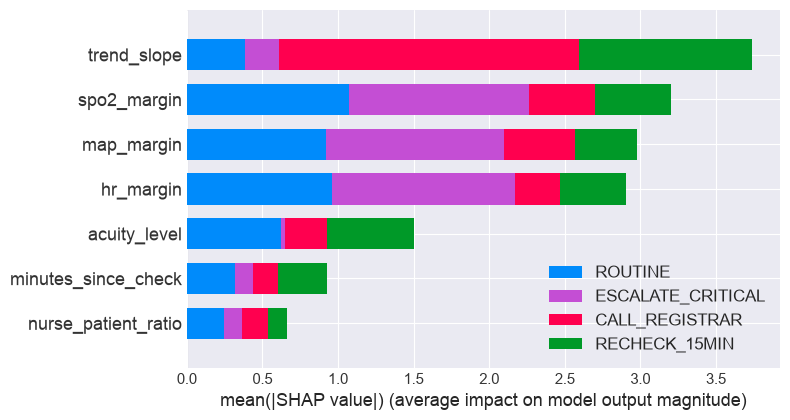

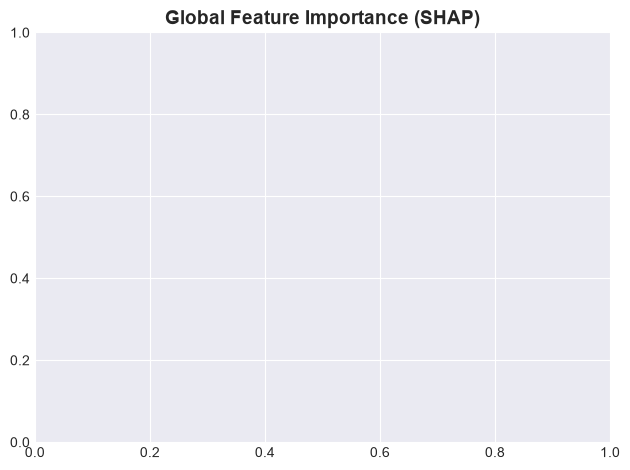

In [16]:
# Summary plot - shows feature importance across all predictions
plt.figure(figsize=(10, 6))
# Use original action names for display
action_names = label_encoder.classes_
shap.summary_plot(shap_values, X_test, plot_type="bar", class_names=action_names)
plt.title('Global Feature Importance (SHAP)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85182/1736415256.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in 

<Figure size 1200x600 with 0 Axes>

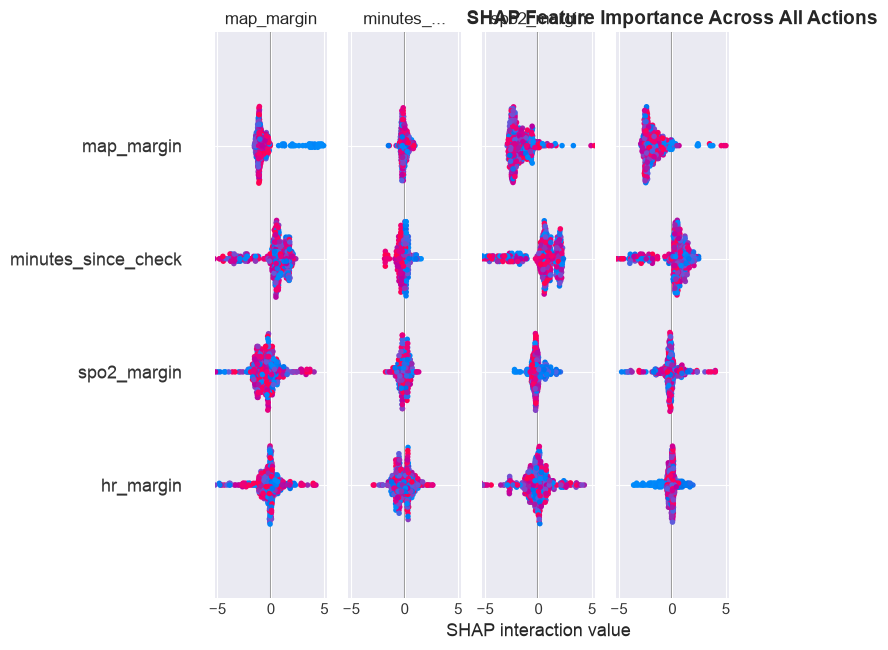


💡 Interpretation:
   - Each point represents a sample
   - Red points: High feature values
   - Blue points: Low feature values
   - X-axis: SHAP value (impact on model prediction)
   - Features sorted by overall importance


In [17]:
# Detailed SHAP summary for each action class
# Note: Due to multi-class output, we'll show overall importance instead of per-class
fig = plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Feature Importance Across All Actions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Interpretation:")
print("   - Each point represents a sample")
print("   - Red points: High feature values")
print("   - Blue points: Low feature values")
print("   - X-axis: SHAP value (impact on model prediction)")
print("   - Features sorted by overall importance")

Sample Bedside Scenario:
spo2_margin             0.818801
map_margin             22.625048
hr_margin              32.356475
minutes_since_check    46.082289
nurse_patient_ratio     3.820230
acuity_level            3.000000
trend_slope            -0.674041
Name: 592, dtype: float64

True Action: CALL_REGISTRAR
Recommended Action: CALL_REGISTRAR

SHAP Waterfall Plot for 'CALL_REGISTRAR' (feature contributions):


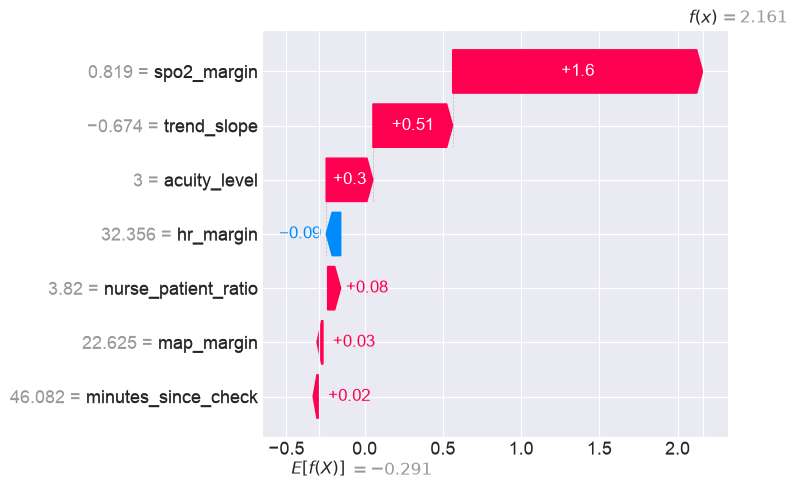


💡 The plot shows how each measurement pushed the model toward, or away from,
   recommending 'Call the medical registrar'.


In [18]:
# Explain a specific escalation decision
sample_idx = 42

print("Sample Bedside Scenario:")
print(X_test.iloc[sample_idx])
print(f"\nTrue Action: {y_test.iloc[sample_idx]}")
print(f"Recommended Action: {y_pred_xgb[sample_idx]}")

# Explain the action the model actually recommended
pred_class = y_pred_xgb[sample_idx]
class_idx = int(np.where(label_encoder.classes_ == pred_class)[0][0])

# Waterfall plot showing feature contributions for this recommendation
print(f"\nSHAP Waterfall Plot for '{pred_class}' (feature contributions):")
shap.plots.waterfall(
    shap.Explanation(
        values=class_shap(shap_values, sample_idx, class_idx),
        base_values=explainer.expected_value[class_idx],
        data=X_test.iloc[sample_idx],
        feature_names=list(X_test.columns)
    ),
    show=False
)
plt.tight_layout()
plt.show()

print("\n\U0001f4a1 The plot shows how each measurement pushed the model toward, or away from,")
print(f"   recommending '{ACTION_LABELS[pred_class]}'.")


Sample Bedside Scenario:
spo2_margin             0.818801
map_margin             22.625048
hr_margin              32.356475
minutes_since_check    46.082289
nurse_patient_ratio     3.820230
acuity_level            3.000000
trend_slope            -0.674041
Name: 592, dtype: float64

True Action: CALL_REGISTRAR
Recommended Action: CALL_REGISTRAR

SHAP Force Plot (shows how features pushed the recommendation):


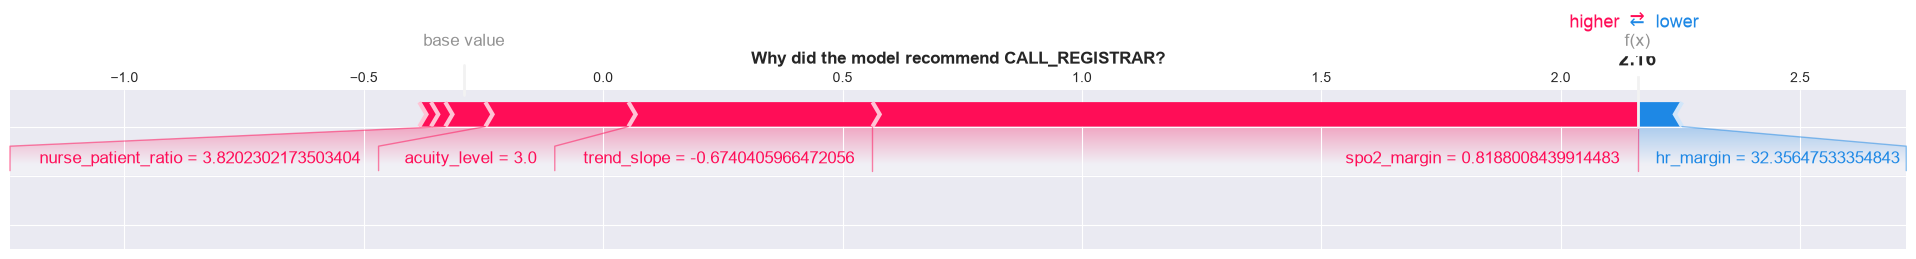

In [19]:
# Explain a specific escalation decision
sample_idx = 42

print("Sample Bedside Scenario:")
print(X_test.iloc[sample_idx])
print(f"\nTrue Action: {y_test.iloc[sample_idx]}")
print(f"Recommended Action: {y_pred_xgb[sample_idx]}")

# Get recommended class index
pred_class = y_pred_xgb[sample_idx]
class_idx = int(np.where(label_encoder.classes_ == pred_class)[0][0])

# Force plot for this recommendation
print("\nSHAP Force Plot (shows how features pushed the recommendation):")
shap.force_plot(
    explainer.expected_value[class_idx],
    class_shap(shap_values, sample_idx, class_idx),
    X_test.iloc[sample_idx],
    matplotlib=True,
    show=False
)
plt.title(f'Why did the model recommend {pred_class}?', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [20]:
def recommend_escalation_action(
    spo2_margin=4.0,
    map_margin=20.0,
    hr_margin=35.0,
    minutes_since_check=20.0,
    nurse_patient_ratio=4.0,
    acuity_level=2,
    trend_slope=0.0
):
    """
    Interactive widget: recommend an escalation action from bedside monitoring margins.

    The left panel is a margin gauge - the same thing a bedside display shows.
    Each bar is one monitored channel, and its length is the headroom left before
    that channel's alarm fires. A bar that crosses zero is already in alarm.
    """
    # Create input features
    features = pd.DataFrame([{
        'spo2_margin': spo2_margin,
        'map_margin': map_margin,
        'hr_margin': hr_margin,
        'minutes_since_check': minutes_since_check,
        'nurse_patient_ratio': nurse_patient_ratio,
        'acuity_level': acuity_level,
        'trend_slope': trend_slope
    }])

    # Get predictions from all models
    dt_pred = dt_model.predict(features)[0]
    rf_pred = rf_model.predict(features)[0]

    # XGBoost prediction (decode from numeric)
    xgb_pred_encoded = xgb_model.predict(features)[0]
    xgb_pred = label_encoder.inverse_transform([xgb_pred_encoded])[0]

    # Get prediction probabilities from XGBoost
    xgb_proba = xgb_model.predict_proba(features)[0]

    # Visualization
    fig = plt.figure(figsize=(16, 6))
    gs = fig.add_gridspec(1, 3, width_ratios=[2, 1, 1])

    # 1. Margin gauge - how close each channel is to its alarm threshold
    ax1 = fig.add_subplot(gs[0])

    # name, margin, full safe band, borderline cut-off, bedside readout
    channels = [
        ('SpO$_2$', spo2_margin, 9.0, 2.0,
         f'{SPO2_ALARM + spo2_margin:.1f} %   (alarm {SPO2_ALARM:.0f} %)'),
        ('MAP', map_margin, 45.0, 8.0,
         f'{MAP_ALARM + map_margin:.0f} mmHg   (alarm {MAP_ALARM:.0f})'),
        ('Heart rate', hr_margin, 72.0, 12.0,
         f'{HR_ALARM - hr_margin:.0f} bpm   (alarm {HR_ALARM:.0f})'),
    ]

    # Shade the region past the alarm threshold
    ax1.axvspan(-0.45, 0, color='#c0392b', alpha=0.10)

    worst = 'SAFE'
    for pos, (name, margin, band, warn, readout) in enumerate(channels[::-1]):
        frac = float(np.clip(margin / band, -0.4, 1.0))
        if margin < 0:
            colour, severity = '#c0392b', 'ALARM'
            worst = 'ALARM'
        elif margin < warn:
            colour, severity = '#e67e22', 'BORDERLINE'
            worst = 'ALARM' if worst == 'ALARM' else 'BORDERLINE'
        else:
            colour, severity = '#27ae60', 'SAFE'

        ax1.barh(pos, frac, height=0.5, color=colour, alpha=0.85)
        ax1.text(1.06, pos, f'{readout}    {severity}',
                 va='center', fontsize=10, fontweight='bold', color=colour)

    ax1.axvline(0, color='firebrick', linewidth=2)
    ax1.axvline(1.0, color='grey', linewidth=1, linestyle=':')
    ax1.set_yticks(range(len(channels)))
    ax1.set_yticklabels([c[0] for c in channels[::-1]], fontsize=12, fontweight='bold')
    ax1.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax1.set_xticklabels(['alarm', '25%', '50%', '75%', 'full\nheadroom'], fontsize=9)
    ax1.set_xlim(-0.5, 2.6)
    ax1.set_ylim(-1.2, len(channels) - 0.3)
    ax1.set_xlabel('Margin to alarm threshold (fraction of the safe band)', fontsize=11)
    ax1.set_title('Bedside Margin Gauge', fontsize=14, fontweight='bold')
    ax1.grid(axis='x', alpha=0.25)

    # Ward context, the way it appears alongside the numbers
    trend_word = 'declining' if trend_slope < -0.5 else ('improving' if trend_slope > 0.5 else 'steady')
    trend_colour = '#c0392b' if trend_slope < -0.5 else ('#27ae60' if trend_slope > 0.5 else '#7f8c8d')
    ax1.text(-0.45, len(channels) - 0.55,
             f'Acuity {int(acuity_level)}/5   |   {nurse_patient_ratio:.1f} patients per nurse'
             f'   |   last checked {minutes_since_check:.0f} min ago'
             f'   |   trend {trend_word} ({trend_slope:+.2f})',
             fontsize=10, fontweight='bold', color=trend_colour, va='bottom')

    # The recommendation itself, displayed as the ward would see it
    banner_colour = {'ALARM': '#c0392b', 'BORDERLINE': '#e67e22', 'SAFE': '#27ae60'}[worst]
    ax1.text(-0.45, -0.95,
             f'RECOMMENDED ACTION:  {ACTION_LABELS[xgb_pred]}',
             fontsize=13, fontweight='bold', color='white', va='center',
             bbox=dict(boxstyle='round,pad=0.5', facecolor=banner_colour, alpha=0.95))

    # 2. Model predictions comparison
    ax2 = fig.add_subplot(gs[1])
    models = ['Decision\nTree', 'Random\nForest', 'XGBoost']
    predictions = [dt_pred, rf_pred, xgb_pred]
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

    bars = ax2.barh(models, [1, 1, 1], color=colors, alpha=0.3)
    ax2.set_xlim(0, 1.5)
    ax2.set_xlabel('')
    ax2.set_title('Model Recommendations', fontsize=12, fontweight='bold')
    ax2.set_xticks([])

    # Add prediction text on bars
    for idx, (bar, pred) in enumerate(zip(bars, predictions)):
        ax2.text(0.5, bar.get_y() + bar.get_height()/2, pred,
                ha='center', va='center', fontsize=10, fontweight='bold')

    # 3. XGBoost probability distribution
    ax3 = fig.add_subplot(gs[2])
    action_names = label_encoder.classes_
    y_pos = np.arange(len(action_names))

    bars = ax3.barh(y_pos, xgb_proba, color='steelblue', alpha=0.7)
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels(action_names, fontsize=9)
    ax3.set_xlabel('Probability', fontsize=10)
    ax3.set_title('XGBoost Confidence', fontsize=12, fontweight='bold')
    ax3.set_xlim(0, 1)

    # Highlight the recommended action
    max_idx = np.argmax(xgb_proba)
    bars[max_idx].set_color('darkgreen')
    bars[max_idx].set_alpha(0.9)

    # Add probability values
    for idx, prob in enumerate(xgb_proba):
        ax3.text(prob + 0.02, idx, f'{prob:.2f}',
                va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

    # Print summary
    print(f"\n{'='*60}")
    print(f"\U0001fa7a RECOMMENDED ACTION: {ACTION_LABELS[xgb_pred]}")
    print(f"   Confidence: {xgb_proba[max_idx]:.1%}")
    print(f"{'='*60}")

# Create interactive widget
interact(
    recommend_escalation_action,
    spo2_margin=FloatSlider(min=-1, max=9, step=0.5, value=4,
                            description='SpO2 margin'),
    map_margin=FloatSlider(min=-5, max=45, step=1, value=20,
                           description='MAP margin'),
    hr_margin=FloatSlider(min=-8, max=72, step=2, value=35,
                          description='HR margin'),
    minutes_since_check=FloatSlider(min=0, max=120, step=5, value=20,
                                    description='Mins since check'),
    nurse_patient_ratio=FloatSlider(min=1, max=8, step=0.5, value=4,
                                    description='Patients/nurse'),
    acuity_level=IntSlider(min=1, max=5, step=1, value=2,
                           description='Acuity (1-5)'),
    trend_slope=FloatSlider(min=-3, max=3, step=0.25, value=0,
                            description='Trend slope')
);


interactive(children=(FloatSlider(value=4.0, description='SpO2 margin', max=9.0, min=-1.0, step=0.5), FloatSli…

## 8. Real-World Considerations

### Safety and Reliability

When deploying an escalation model in a real clinical setting:

1. **Safety Constraints**
   - Keep the hard-coded policy rules (a breached threshold always escalates)
   - The model should augment, never replace, the escalation policy or clinical judgement
   - Fail safe when a monitoring channel drops out: absent data is not reassuring data

2. **Model Validation**
   - Validate retrospectively against recorded escalations before any prospective use
   - Test edge cases (several channels borderline at once, artefact, disconnected probes)
   - Run silently alongside the ward first and compare with what clinicians actually did

3. **Uncertainty Quantification**
   - Use the predicted probabilities to express confidence
   - Fall back to the more cautious action when confidence is low
   - Monitor for patients unlike anything in the training data

4. **Data Quality**
   - Real monitoring data is noisy: motion artefact, poor probe contact, charting lag
   - Account for drift between devices and calibration differences
   - Collect training data covering every ward, every shift and every season

5. **Alarm Burden**
   - An over-eager model is worse than none: alarm fatigue is a measured patient safety harm
   - Track how many recommendations are acted on, not just how many are correct
   - Tune the operating point with the ward, not in isolation

### Next Steps for Deployment

- **Collect real escalation decisions** with the observations that prompted them
- **Add temporal features** (the previous hour of observations, not just a single slope)
- **Model the outcome as well as the action** (did escalation change what happened?)
- **Integrate with the electronic record** so the recommendation lands where it is read
- **Audit continuously** for drift and for disparities between patient groups


## Summary

### What We Learned

✅ **Problem Formulation**: Turned a bedside escalation decision into a supervised classification task

✅ **Data Generation**: Created synthetic monitoring margins labelled by a written escalation policy

✅ **Model Training**: Built and compared Decision Trees, Random Forest, and XGBoost classifiers

✅ **Visualization**: Built a margin gauge that shows headroom the way a bedside display does

✅ **Interpretation**: Used SHAP values to understand which channels drive the recommendation

✅ **Interactive Exploration**: Built hands-on tools for experimenting with bedside scenarios

### Key Takeaways

1. **A tree can recover written clinical rules from examples alone** - compare the thresholds it split on with the policy we wrote
2. **Margins to threshold are the right feature**, not raw values: they carry the clinical meaning directly
3. **Ensemble methods** (Random Forest, XGBoost) generally outperform a single decision tree
4. **Interpretability is not optional** when a model recommends an action on a real patient
5. **Deployment needs validation, hard safety rules, and attention to alarm burden**

### Applications Beyond the Ward

The same framing applies wherever a threshold-based protocol drives an action:
- Emergency department triage category assignment
- Anesthetic and post-operative recovery step-down decisions
- Dialysis and infusion protocol adjustments
- Remote monitoring and hospital-at-home escalation
- Community and care-home deterioration alerting

---

**Next Steps**: Try changing the escalation policy, adding a monitoring channel, or modelling
a sequence of observations rather than a single moment in time. 🩺
